# LiDAR and Point Clouds from Zero

> **Who is this for:** AI and software engineers who have never worked with LiDAR or 3D point clouds. You need basic Python, numpy and a little school geometry (sine, cosine).
>
> **What you will learn:**
> - how **LiDAR** measures distance with **time of flight**, and the main sensor types (spinning, solid-state, **FMCW LiDAR**), wavelengths (905 nm vs 1550 nm), **beams / channels**, range and **intensity**
> - what a **point cloud** is, **organized vs unorganized** clouds, and how to convert **ranges and angles into x, y, z**
> - how to **simulate a spinning LiDAR** in a toy street scene (ground, cars, poles, pedestrians, a wall), with noise and occlusion
> - the classic processing pipeline, all implemented in numpy / scipy / scikit-learn: **crop**, **voxel-grid downsampling**, **statistical outlier removal**, **RANSAC ground segmentation**, **DBSCAN clustering**, **bounding boxes**, **bird's-eye-view (BEV) maps**
> - how to align two scans with **ICP** (Iterative Closest Point), and the idea behind **mapping and SLAM**
> - how deep learning reads point clouds: a tiny **PointNet** forward pass that proves **permutation invariance**, plus the ideas of **VoxelNet, PointPillars and BEV transformers**
> - how to **classify clusters** (car / pedestrian / pole) with hand-made features and a random forest
> - **LiDAR vs radar vs camera**, real applications, and the tools people use (Open3D, PCL, ROS)
>
> **Prerequisites:** [01_signals_frequency_and_sensor_basics.ipynb](01_signals_frequency_and_sensor_basics.ipynb) (sampling, noise), [Linear algebra](../14_Mathematics/01_linear_algebra.ipynb) (vectors, rotation matrices, SVD), [Clustering](../03_Machine_Learning/02_unsupervised/01_clustering.ipynb) (DBSCAN). Helpful: [03_radar_fmcw_range_doppler_and_micro_doppler.ipynb](03_radar_fmcw_range_doppler_and_micro_doppler.ipynb) for the FMCW idea.
>
> **Time needed:** about 2-3 hours to read and play. The notebook itself runs in well under a minute.
>
> **Runs on:** CPU, no API key, no internet. Only numpy, scipy, pandas, scikit-learn and matplotlib. No LiDAR hardware and no dataset download: we build our own scene.

## 0. Setup

We use numpy for the geometry, scipy for fast nearest-neighbour search (`cKDTree`), scikit-learn for DBSCAN and the classifier, and matplotlib for plots. A fixed seed makes every run give the same numbers.

In [1]:
import time
import numpy as np                          # arrays, geometry
import pandas as pd                         # small result tables
import matplotlib.pyplot as plt             # plots
from scipy.spatial import cKDTree           # fast nearest-neighbour search
from sklearn.cluster import DBSCAN          # density-based clustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

SEED = 7
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 90
T_START = time.time()
print("numpy", np.__version__)

numpy 2.5.4


## 1. What is LiDAR? Time of flight

**What it is.** **LiDAR** (Light Detection And Ranging) is a sensor that measures distance with laser light. It sends a short laser **pulse**, waits for the reflection, and measures how long the round trip took. This is called **time of flight (ToF)**.

**Simple analogy.** Shout in a canyon and count the seconds until the echo comes back. Sound is slow, so the echo takes seconds. Light is about a million times faster, so a LiDAR has to measure **nanoseconds** (billionths of a second).

**How it works.**

1. A laser diode fires a pulse a few nanoseconds long.
2. The pulse hits a surface and part of the light bounces back.
3. A photodetector catches the weak echo and a timer records the delay $\Delta t$.
4. The light travelled to the target **and back**, so the distance is

$$ d = \frac{c \cdot \Delta t}{2}, \qquad c \approx 3 \times 10^8 \ \text{m/s} $$

5. The strength of the echo is also recorded. It is called **intensity** (or **reflectivity** after calibration) and tells you how "shiny" the surface is for that laser: lane paint and road signs return strong echoes, dark tyres and asphalt return weak ones.

```mermaid
flowchart LR
    A[Laser fires pulse] --> B[Light travels to object]
    B --> C[Object reflects part of the light]
    C --> D[Detector receives echo]
    D --> E[Timer gives delay dt]
    E --> F[distance = c * dt / 2<br/>plus intensity of echo]
```

The code below shows how tiny the times are, and why timing precision decides range precision.

In [2]:
C_LIGHT = 299_792_458.0          # speed of light in m/s

for d in [1, 10, 50, 100, 200]:
    dt = 2 * d / C_LIGHT         # round-trip time
    print(f"target at {d:4d} m -> echo after {dt*1e9:8.1f} ns")

# If our timer can only tell times apart in steps of 1 ns, how fine is the distance step?
timing_step = 1e-9
print(f"\n1 ns timing step -> distance step of {C_LIGHT * timing_step / 2 * 100:.1f} cm")

# If we fire a new pulse every 1 microsecond, an echo from far away can be confused with the NEXT pulse.
pulse_period = 1e-6
print(f"pulse every 1 us -> maximum unambiguous range {C_LIGHT * pulse_period / 2:.0f} m")

target at    1 m -> echo after      6.7 ns
target at   10 m -> echo after     66.7 ns
target at   50 m -> echo after    333.6 ns
target at  100 m -> echo after    667.1 ns
target at  200 m -> echo after   1334.3 ns

1 ns timing step -> distance step of 15.0 cm
pulse every 1 us -> maximum unambiguous range 150 m


Two lessons from these numbers:

- A 1 ns timing error is already 15 cm of distance error. Real sensors use fast electronics and averaging to reach a few centimetres.
- Firing faster gives more points per second, but the maximum range you can measure without confusion gets shorter. Sensor designers trade these against each other.

## 2. Kinds of LiDAR, wavelengths, beams and range

### 2.1 How the beam is moved: spinning vs solid-state

One laser measures one point. To get a 3D picture the sensor must point the beam in many directions.

| Type | What it is | Good | Not so good |
|---|---|---|---|
| **Spinning (mechanical)** | A stack of lasers (16 to 128 **channels**, also called **beams**) rotates, usually 10 times per second | 360 degree view, mature, well understood | moving parts, bulky, costly |
| **MEMS mirror** | A tiny tilting mirror on a chip steers one or a few lasers | small, cheaper, no big rotating part | limited field of view (for example about 120 degrees) |
| **Flash** | One wide laser flash lights the whole scene, a sensor array (like a camera chip) times every pixel | no moving parts at all, captures all points at the same instant | shorter range, because the light is spread out |
| **Optical phased array (OPA)** | Steers light electronically by shifting the phase across many tiny emitters | fully solid-state | still maturing |

"**Solid-state**" means few or no moving parts. Most car makers want solid-state units because they are cheaper and easier to hide in a car body.

### 2.2 Pulsed (ToF) vs FMCW LiDAR

Most LiDARs are **pulsed ToF**: they time short pulses, as in section 1.

**FMCW LiDAR** (Frequency-Modulated Continuous Wave) works like the FMCW radar in [notebook 03](03_radar_fmcw_range_doppler_and_micro_doppler.ipynb), but with light. The laser frequency is swept in a "chirp". The echo is mixed with the outgoing light; the **beat frequency** gives the range, and the **Doppler shift** gives the **radial velocity** of every single point. So each point carries a speed as well as a position. It is also less disturbed by sunlight and other LiDARs. The cost is more complex optics.

### 2.3 Wavelength: 905 nm vs 1550 nm

Both are infrared, so humans cannot see the beam. The choice is mostly about **eye safety**, detectors and cost.

| | ~905 nm | ~1550 nm |
|---|---|---|
| Detector | cheap silicon | more expensive InGaAs (indium gallium arsenide) |
| Eye safety | light can reach the retina, so power is strictly limited | mostly absorbed in the front of the eye, so more power is allowed |
| Typical effect | lower cost, shorter range | longer range possible, higher cost |
| Water | absorbed less | absorbed more strongly, so rain and wet surfaces affect it differently |

### 2.4 Specs you will see on a datasheet

| Spec | Meaning | Typical values (illustrative) |
|---|---|---|
| **Channels / beams** | number of lasers stacked vertically = rows in the scan | 16, 32, 64, 128 |
| **Vertical field of view** | angle covered from the lowest to the highest beam | 25 to 45 degrees |
| **Horizontal resolution** | angle between two firings while spinning | 0.1 to 0.4 degrees |
| **Frame rate** | full rotations per second | 10 Hz is common |
| **Range** | how far it can see, usually quoted for a 10% reflective target | 100 to 250 m |
| **Range accuracy** | typical distance error | a few cm |
| **Returns** | how many echoes per pulse it reports (first, strongest, last) | 1 to 3 |

**Multiple returns** matter in forests and rain: one pulse can partly hit a leaf (first return) and partly the ground behind it (last return).

## 3. Point clouds: x, y, z, intensity

**What it is.** A **point cloud** is simply a list of 3D points. Each row is one echo: `[x, y, z, intensity]` (sometimes also time, ring number, or velocity for FMCW LiDAR). As a numpy array it has shape `(N, 4)`.

**Simple analogy.** Imagine throwing thousands of tiny paint dots at a room from one spot. Where the dots stick, you get the room's shape, but only the parts you could see, and only as dots, not surfaces.

**Organized vs unorganized.**

| | Organized point cloud | Unorganized point cloud |
|---|---|---|
| Shape | 2D grid, like an image: `(beams, azimuth_steps)` | flat list: `(N, 3 or 4)` |
| Neighbours | known for free (pixel next to pixel) | must be searched (k-d tree) |
| Missing echoes | stored as NaN / 0 in the grid | simply absent |
| Comes from | a single spinning scan; called a **range image** | merged scans, maps, after filtering |

**From ranges to x, y, z (spherical to Cartesian).** The sensor really measures a **range** $r$ along a known direction: **azimuth** $\theta$ (left-right angle) and **elevation** $\varphi$ (up-down angle of that beam). With x forward, y left, z up:

$$ x = r\cos\varphi\cos\theta,\qquad y = r\cos\varphi\sin\theta,\qquad z = r\sin\varphi $$

```
           z (up)
           |      * point
           |     /|
           |  r / | z = r sin(elev)
           |   /  |
           |  / elev
  sensor   o------+------> x (forward), seen from the side
```

In [3]:
def ranges_to_xyz(r, elev, azim):
    """Convert range + elevation + azimuth (radians) into x, y, z.
    Works for single numbers or whole arrays (broadcasting)."""
    x = r * np.cos(elev) * np.cos(azim)
    y = r * np.cos(elev) * np.sin(azim)
    z = r * np.sin(elev) + 0 * azim          # "+ 0 * azim" just gives z the same shape as x and y
    return np.stack([x, y, z], axis=-1)

# Three example echoes
r = np.array([10.0, 10.0, 5.0])
elev = np.deg2rad([0.0, -10.0, 5.0])
azim = np.deg2rad([0.0, 90.0, 45.0])
for ri, e, a, p in zip(r, elev, azim, ranges_to_xyz(r, elev, azim)):
    print(f"r={ri:5.1f} m  elev={np.rad2deg(e):5.1f} deg  azim={np.rad2deg(a):5.1f} deg  ->  xyz = {p}")

# And back again: xyz -> range is just the length of the vector
print("range recovered:", np.linalg.norm(ranges_to_xyz(r, elev, azim), axis=1))

r= 10.0 m  elev=  0.0 deg  azim=  0.0 deg  ->  xyz = [10.  0.  0.]
r= 10.0 m  elev=-10.0 deg  azim= 90.0 deg  ->  xyz = [ 0.     9.848 -1.736]
r=  5.0 m  elev=  5.0 deg  azim= 45.0 deg  ->  xyz = [3.522 3.522 0.436]
range recovered: [10. 10.  5.]


## 4. A synthetic street scene and a simulated spinning LiDAR

Real LiDAR datasets (KITTI, nuScenes, Waymo Open Dataset) are large downloads. Instead we **simulate** one, which also teaches how the sensor sees the world.

**How the simulator works (ray casting).**

1. The sensor has 32 beams with elevations from -24 to +8 degrees, and fires every 0.4 degrees of azimuth: 32 x 900 = 28,800 rays per turn.
2. For every ray we compute where it first hits: the ground plane, a box (car, wall) or a vertical cylinder (pole, pedestrian).
3. The **nearest** hit wins. Anything behind it is hidden. This gives realistic **occlusion** (shadows behind objects).
4. We add realism: small range noise, some rays with no echo (**dropout**, for example dark or mirror-like surfaces), and a few random spurious echoes (**outliers**, for example dust or rain).
5. Intensity = surface reflectivity x cos(angle of incidence) + noise. Surfaces hit at a grazing angle return weaker echoes.

The world frame has the ground at z = 0. The sensor sits on a car roof at 1.8 m height. Points are returned in the **sensor frame** (x forward, y left, z up, origin at the sensor), so the ground appears at z = -1.8 m.

In [4]:
SENSOR_HEIGHT = 1.8
N_BEAMS, N_AZ = 32, 900
ELEV = np.deg2rad(np.linspace(-24, 8, N_BEAMS))                 # one elevation per beam (row)
AZIM = np.deg2rad(np.arange(N_AZ) * 360 / N_AZ - 180)           # one azimuth per firing (column)
MAX_RANGE = 60.0

# Unit direction of every ray in the SENSOR frame, shape (32, 900, 3)
RAY_DIRS = ranges_to_xyz(1.0, ELEV[:, None], AZIM[None, :])

def ray_box(o, d, obj):
    """Distance along each ray to an oriented box (slab method). Returns (t, cos_incidence)."""
    cx, cy = obj["center"]; l, w, h = obj["size"]; z0 = obj.get("z0", 0.0)
    c, s = np.cos(obj["yaw"]), np.sin(obj["yaw"])
    # Move ray origin and directions into the box's own frame (box axis-aligned, centred at 0)
    ox, oy = o[0] - cx, o[1] - cy
    lo = np.array([c * ox + s * oy, -s * ox + c * oy, o[2] - (z0 + h / 2)])
    ld = np.stack([c * d[:, 0] + s * d[:, 1], -s * d[:, 0] + c * d[:, 1], d[:, 2]], axis=1)
    half = np.array([l / 2, w / 2, h / 2])
    with np.errstate(divide="ignore", invalid="ignore"):
        t1, t2 = (-half - lo) / ld, (half - lo) / ld
    t_near, t_far = np.minimum(t1, t2), np.maximum(t1, t2)
    t_enter, t_exit = np.nanmax(t_near, axis=1), np.nanmin(t_far, axis=1)
    hit = (t_exit >= t_enter) & (t_enter > 0)
    face = np.nanargmax(t_near, axis=1)                          # which face the ray entered through
    cos_inc = np.abs(ld[np.arange(len(ld)), face])
    return np.where(hit, t_enter, np.inf), cos_inc

def ray_cylinder(o, d, obj):
    """Distance along each ray to a vertical cylinder standing on the ground."""
    cx, cy = obj["center"]; r, h = obj["radius"], obj["height"]
    ox, oy = o[0] - cx, o[1] - cy
    a = d[:, 0] ** 2 + d[:, 1] ** 2
    b = 2 * (ox * d[:, 0] + oy * d[:, 1])
    c0 = ox ** 2 + oy ** 2 - r ** 2
    disc = b * b - 4 * a * c0
    with np.errstate(invalid="ignore", divide="ignore"):
        t = (-b - np.sqrt(disc)) / (2 * a)
        z = o[2] + t * d[:, 2]
        cos_inc = np.abs((ox + t * d[:, 0]) * d[:, 0] + (oy + t * d[:, 1]) * d[:, 1]) / r
    hit = (disc > 0) & (t > 0) & (z >= 0) & (z <= h)
    return np.where(hit, t, np.inf), np.nan_to_num(cos_inc)

print("rays per scan:", RAY_DIRS.shape[0] * RAY_DIRS.shape[1])

rays per scan: 28800


In [5]:
# The toy street. Positions are in metres in the WORLD frame (ground at z = 0).
SCENE = [
    dict(name="car_1", cls="car", kind="box", center=(12, -3.0), size=(4.5, 1.8, 1.5), z0=0.25, yaw=np.deg2rad(8),  refl=0.55),
    dict(name="car_2", cls="car", kind="box", center=(9, 5.5),   size=(4.2, 1.8, 1.4), z0=0.25, yaw=np.deg2rad(-3), refl=0.60),
    dict(name="car_3", cls="car", kind="box", center=(-11, -4),  size=(4.8, 1.9, 1.6), z0=0.25, yaw=np.deg2rad(90), refl=0.50),
    dict(name="car_4", cls="car", kind="box", center=(21, -3.5), size=(4.4, 1.8, 1.5), z0=0.25, yaw=np.deg2rad(0),  refl=0.55),
    dict(name="wall",  cls="building", kind="box", center=(2, 16), size=(40, 1.0, 5.0), yaw=0.0, refl=0.35),
    dict(name="pole_1", cls="pole", kind="cyl", center=(6, -6.5),  radius=0.15, height=5.0, refl=0.80),
    dict(name="pole_2", cls="pole", kind="cyl", center=(-5, 7.0),  radius=0.15, height=5.0, refl=0.80),
    dict(name="pole_3", cls="pole", kind="cyl", center=(25, 6.0),  radius=0.12, height=4.5, refl=0.80),
    dict(name="ped_1", cls="pedestrian", kind="cyl", center=(5, 1.5),  radius=0.30, height=1.75, refl=0.40),
    dict(name="ped_2", cls="pedestrian", kind="cyl", center=(16, 3.0), radius=0.28, height=1.70, refl=0.40),
    dict(name="ped_3", cls="pedestrian", kind="cyl", center=(-7, -9), radius=0.30, height=1.80, refl=0.40),
]
GROUND_REFL = 0.20

In [6]:
def lidar_scan(scene, sensor_xy=(0.0, 0.0), sensor_yaw=0.0, rng=rng,
               range_noise=0.02, dropout=0.03, outlier_rate=0.002):
    """Simulate one 360-degree scan. Returns an ORGANIZED scan (range image + labels + intensity)."""
    c, s = np.cos(sensor_yaw), np.sin(sensor_yaw)
    d_sensor = RAY_DIRS.reshape(-1, 3)
    # rotate ray directions from sensor frame into world frame (yaw only)
    d = np.stack([c * d_sensor[:, 0] - s * d_sensor[:, 1], s * d_sensor[:, 0] + c * d_sensor[:, 1], d_sensor[:, 2]], axis=1)
    o = np.array([sensor_xy[0], sensor_xy[1], SENSOR_HEIGHT])

    # candidate hits: ground first, then every object
    with np.errstate(divide="ignore"):
        t_ground = np.where(d[:, 2] < 0, -o[2] / d[:, 2], np.inf)
    ts, coss, refls = [t_ground], [np.abs(d[:, 2])], [GROUND_REFL]
    for obj in scene:
        t, ci = ray_box(o, d, obj) if obj["kind"] == "box" else ray_cylinder(o, d, obj)
        ts.append(t); coss.append(ci); refls.append(obj["refl"])
    ts, coss = np.stack(ts), np.stack(coss)
    first = np.argmin(ts, axis=0)                    # nearest surface wins -> occlusion
    t = ts[first, np.arange(ts.shape[1])]
    cos_inc = coss[first, np.arange(ts.shape[1])]
    label = first.astype(int)                        # 0 = ground, k = scene[k-1]

    # sensor imperfections
    t = t + rng.normal(0, range_noise, t.shape)
    intensity = np.clip(np.array(refls)[first] * cos_inc + rng.normal(0, 0.03, t.shape), 0, 1)
    no_echo = (t > MAX_RANGE) | (rng.random(t.shape) < dropout)
    t[no_echo] = np.nan; label[no_echo] = -1
    spurious = rng.random(t.shape) < outlier_rate    # dust / rain: random short echoes
    t[spurious] = rng.uniform(1, 30, spurious.sum()); label[spurious] = -2; intensity[spurious] = rng.uniform(0, 0.2, spurious.sum())
    shape = RAY_DIRS.shape[:2]
    return dict(range=t.reshape(shape), label=label.reshape(shape), intensity=intensity.reshape(shape))

def to_point_cloud(scan):
    """ORGANIZED range image -> UNORGANIZED (N, 4) point cloud [x, y, z, intensity] + labels."""
    xyz = ranges_to_xyz(scan["range"], ELEV[:, None], AZIM[None, :])     # (32, 900, 3), NaN where no echo
    valid = ~np.isnan(scan["range"])
    pts = np.column_stack([xyz[valid], scan["intensity"][valid]])
    return pts, scan["label"][valid]

t0 = time.time()
scan1 = lidar_scan(SCENE)
P, LAB = to_point_cloud(scan1)
print(f"simulated in {time.time()-t0:.2f} s")
print("organized range image shape:", scan1["range"].shape, "-> unorganized cloud shape:", P.shape)
print("rays with no echo:", int(np.isnan(scan1["range"]).sum()), " spurious outlier echoes:", int((LAB == -2).sum()))

# A readable class name for every point
OBJ_CLS = np.array(["ground"] + [o["cls"] for o in SCENE])
OBJ_NAME = np.array(["ground"] + [o["name"] for o in SCENE])
NAMES = np.where(LAB >= 0, OBJ_NAME[np.maximum(LAB, 0)], "outlier")      # object name per point
NAME_TO_CLS = {"ground": "ground", "outlier": "outlier", **{o["name"]: o["cls"] for o in SCENE}}
def names_to_cls(names):
    return np.array([NAME_TO_CLS[n] for n in names])
CLS = names_to_cls(NAMES)                                                  # class per point
print(pd.Series(CLS).value_counts().to_string())

simulated in 0.04 s
organized range image shape: (32, 900) -> unorganized cloud shape: (22061, 4)
rays with no echo: 6739  spurious outlier echoes: 55


ground        16848
building       3339
car            1236
pedestrian      385
pole            198
outlier          55


Let's look at the scan three ways: the **range image** (organized form), a **top-down view**, and a **3D view**. Notice the **shadows** behind cars and poles: the LiDAR cannot see through objects, so there are no ground points there. Notice also that the rings of ground points get further apart with distance: far objects get few points.

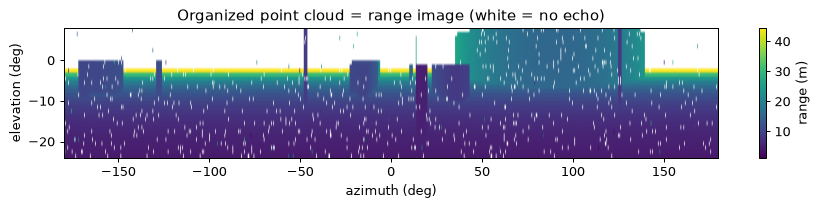

In [7]:
fig, ax = plt.subplots(figsize=(10, 2.4))
im = ax.imshow(scan1["range"], aspect="auto", cmap="viridis",
               extent=[-180, 180, np.rad2deg(ELEV[0]), np.rad2deg(ELEV[-1])], origin="lower")
ax.set_xlabel("azimuth (deg)"); ax.set_ylabel("elevation (deg)")
ax.set_title("Organized point cloud = range image (white = no echo)")
plt.colorbar(im, ax=ax, label="range (m)"); plt.tight_layout(); plt.show()

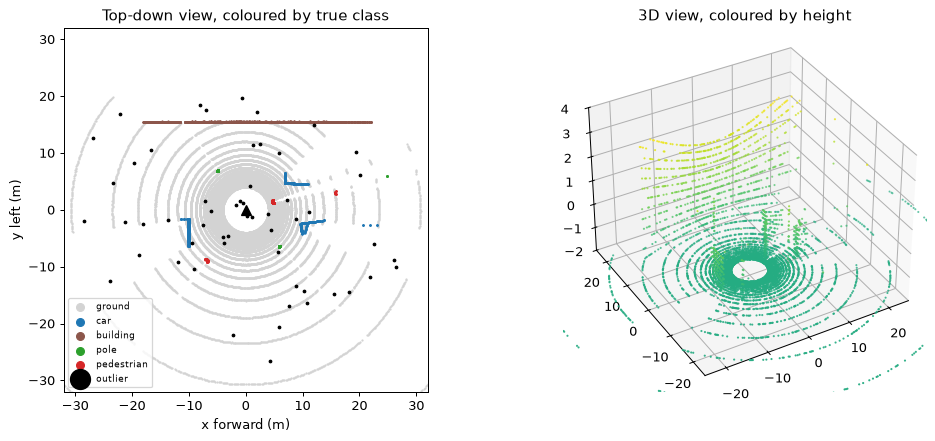

In [8]:
CLASS_COLORS = {"ground": "lightgray", "car": "tab:blue", "building": "tab:brown",
                "pole": "tab:green", "pedestrian": "tab:red", "outlier": "black"}

def plot_topdown(pts, cls, ax, title, lim=32, s=0.6):
    for name, col in CLASS_COLORS.items():
        m = cls == name
        if m.any():
            ax.scatter(pts[m, 0], pts[m, 1], s=s if name != "outlier" else 4, c=col, label=name)
    ax.plot(0, 0, "k^", ms=8)                  # the sensor
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel("x forward (m)"); ax.set_ylabel("y left (m)"); ax.set_title(title)

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1)
plot_topdown(P, CLS, ax1, "Top-down view, coloured by true class")
ax1.legend(markerscale=8, fontsize=7, loc="lower left")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
sub = rng.choice(len(P), 7000, replace=False)                 # subsample so the 3D plot is fast
ax2.scatter(P[sub, 0], P[sub, 1], P[sub, 2], c=P[sub, 2], s=0.5, cmap="viridis")
ax2.set_xlim(-25, 25); ax2.set_ylim(-25, 25); ax2.set_zlim(-2, 4)
ax2.view_init(elev=35, azim=-120); ax2.set_title("3D view, coloured by height")
plt.tight_layout(); plt.show()

## 5. Preprocessing: crop, voxel downsampling, outlier removal

Raw clouds are big and noisy. Three cheap steps make everything after them faster and cleaner.

**5.1 Crop (region of interest).** Keep only points inside a box you care about, for example 35 m around the car and below 4 m above the sensor. Real pipelines also remove points that hit the ego car itself.

**5.2 Voxel-grid downsampling.**
- *What it is:* split space into small cubes (**voxels**, "volume pixels") and replace all points in one cube by their average.
- *Analogy:* like lowering the resolution of a photo; nearby dense points (close to the sensor) are merged, sparse far points mostly stay.
- *When to use:* before slow steps (ICP, clustering, neural networks). *When not:* if you need every point on a small far object.

**5.3 Statistical outlier removal (SOR).**
- *What it is:* for each point, compute the mean distance to its k nearest neighbours. Points whose mean distance is much larger than usual (mean + 2 standard deviations) are isolated and probably noise.
- *Analogy:* a person standing alone in an empty field is suspicious in a crowd photo.
- *Caution:* very far real objects are also sparse and can be removed by mistake.

In [9]:
def crop(pts, labels, xy_lim=35.0, z_max=4.0):
    m = (np.abs(pts[:, 0]) < xy_lim) & (np.abs(pts[:, 1]) < xy_lim) & (pts[:, 2] < z_max)
    return pts[m], labels[m]

def voxel_downsample(pts, labels, voxel=0.2):
    """Average all points that fall in the same voxel. Keep the label of the first point."""
    keys = np.floor(pts[:, :3] / voxel).astype(np.int64)
    _, first, inverse = np.unique(keys, axis=0, return_index=True, return_inverse=True)
    inverse = inverse.ravel()
    counts = np.bincount(inverse)
    out = np.zeros((len(first), pts.shape[1]))
    for j in range(pts.shape[1]):
        out[:, j] = np.bincount(inverse, weights=pts[:, j]) / counts
    return out, labels[first]

def statistical_outlier_removal(pts, k=8, n_std=2.0):
    tree = cKDTree(pts[:, :3])
    dist, _ = tree.query(pts[:, :3], k=k + 1)          # first neighbour is the point itself
    mean_d = dist[:, 1:].mean(axis=1)
    keep = mean_d < mean_d.mean() + n_std * mean_d.std()
    return keep

# We carry the true object NAME of every point along, only to check our results later.
Pc, Nc = crop(P, NAMES)
Pv, Nv = voxel_downsample(Pc, Nc, voxel=0.2)
keep = statistical_outlier_removal(Pv)
Pf, Nf = Pv[keep], Nv[keep]
Lv, Lf = names_to_cls(Nv), names_to_cls(Nf)                               # class labels

print(f"raw points:            {len(P):6d}")
print(f"after crop:            {len(Pc):6d}")
print(f"after 0.2 m voxels:    {len(Pv):6d}")
print(f"after outlier removal: {len(Pf):6d}")
print(f"spurious outliers: {np.sum(Lv=='outlier')} before SOR -> {np.sum(Lf=='outlier')} after SOR")
print("real (non-outlier) points removed by SOR:", int(np.sum((~keep) & (Lv != 'outlier'))))

raw points:             22061
after crop:             21674
after 0.2 m voxels:     12388
after outlier removal:  12249
spurious outliers: 55 before SOR -> 8 after SOR
real (non-outlier) points removed by SOR: 92


SOR removes most of the dust echoes, but also some real points. This is the usual trade-off: a stricter threshold removes more noise **and** more real far-away points. Always check what a filter throws away.

## 6. Ground segmentation with RANSAC plane fitting

**What it is.** Most LiDAR points on a street are road. Before looking for objects we remove the **ground**. **RANSAC** (RANdom SAmple Consensus) fits a model (here a plane) to data that contains many points that do **not** belong to it.

**Simple analogy.** You want to find the table top in a messy photo. Pick 3 random spots, imagine the flat surface through them, and count how many other spots lie on it. Repeat many times; keep the guess with the most supporters.

**How it works.**
1. Pick 3 random points. They define a plane $n \cdot p + d = 0$ ($n$ is the unit normal).
2. Count **inliers**: points with distance $|n \cdot p + d| <$ threshold (for example 0.15 m).
3. Repeat N times, keep the plane with the most inliers.
4. Refine: fit a least-squares plane to all inliers (the normal is the direction of smallest spread, from an SVD).

How many tries N are needed? If a fraction $w$ of points are ground and you want success probability $p$:

$$ N = \frac{\log(1-p)}{\log(1-w^3)} $$

**When to use / when not.** A single plane works on flat roads. Hills, ramps and curbs need a piecewise approach: fit planes in small patches or rings, or use grid-based height methods. Learned segmentation networks are used in production too.

In [10]:
for w in [0.3, 0.5, 0.7]:
    print(f"ground fraction {w:.1f}: need about {np.log(1-0.99)/np.log(1-w**3):5.0f} tries for 99% success")

def ransac_plane(pts, n_iter=100, thresh=0.15, max_tilt_deg=15, rng=rng):
    """Find the dominant roughly-horizontal plane. Returns normal n, offset d, inlier mask."""
    xyz = pts[:, :3]
    best_count, best = -1, None
    min_nz = np.cos(np.deg2rad(max_tilt_deg))
    for _ in range(n_iter):
        a, b, c_ = xyz[rng.choice(len(xyz), 3, replace=False)]
        n = np.cross(b - a, c_ - a)
        norm = np.linalg.norm(n)
        if norm < 1e-6:
            continue                                 # the 3 points were on a line
        n = n / norm
        if abs(n[2]) < min_nz:
            continue                                 # too steep to be ground (a wall, a car side)
        d = -n @ a
        count = np.sum(np.abs(xyz @ n + d) < thresh)
        if count > best_count:
            best_count, best = count, (n, d)
    n, d = best
    # refine with least squares on the inliers: normal = direction of smallest spread
    inl = np.abs(xyz @ n + d) < thresh
    centroid = xyz[inl].mean(axis=0)
    _, _, Vt = np.linalg.svd(xyz[inl] - centroid, full_matrices=False)
    n = Vt[-1] if Vt[-1][2] > 0 else -Vt[-1]
    d = -n @ centroid
    return n, d, np.abs(xyz @ n + d) < thresh

n_g, d_g, is_ground = ransac_plane(Pf)
print("\nplane normal:", n_g, " offset d:", round(d_g, 3), "-> ground height in sensor frame:", round(-d_g / n_g[2], 3), "m")
true_ground = Lf == "ground"
print(f"ground recall    (true ground found):         {np.mean(is_ground[true_ground]):.3f}")
print(f"ground precision (predicted ground is ground): {np.mean(true_ground[is_ground]):.3f}")

ground fraction 0.3: need about   168 tries for 99% success
ground fraction 0.5: need about    34 tries for 99% success
ground fraction 0.7: need about    11 tries for 99% success

plane normal: [-0. -0.  1.]  offset d: 1.799 -> ground height in sensor frame: -1.799 m
ground recall    (true ground found):         1.000
ground precision (predicted ground is ground): 0.989


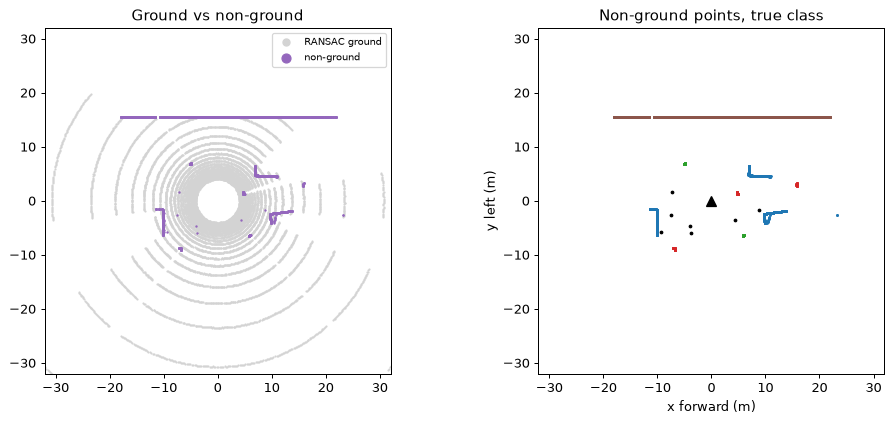

In [11]:
Pobj, Lobj, Nobj = Pf[~is_ground], Lf[~is_ground], Nf[~is_ground]       # everything that is NOT ground
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].scatter(Pf[is_ground, 0], Pf[is_ground, 1], s=0.5, c="lightgray", label="RANSAC ground")
axes[0].scatter(Pobj[:, 0], Pobj[:, 1], s=0.8, c="tab:purple", label="non-ground")
axes[0].set_aspect("equal"); axes[0].set_xlim(-32, 32); axes[0].set_ylim(-32, 32)
axes[0].legend(markerscale=8, fontsize=8); axes[0].set_title("Ground vs non-ground")
plot_topdown(Pobj, Lobj, axes[1], "Non-ground points, true class", s=1.5)
plt.tight_layout(); plt.show()

## 7. Object clustering with DBSCAN

**What it is.** After removing the ground, the remaining points form separate "blobs": one per object. **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) groups points that are close together, without needing to know how many objects there are. Points that are alone are labelled noise (-1).

**Simple analogy.** Islands on a map: everything connected by land within a short walk (`eps`) is one island. A tiny rock with fewer than `min_samples` neighbours is not an island.

**How it works.** A point with at least `min_samples` neighbours within distance `eps` is a **core point**. Clusters grow by connecting core points and their neighbours. See [01_clustering.ipynb](../03_Machine_Learning/02_unsupervised/01_clustering.ipynb) for the general algorithm.

**When to use / when not.** Great for LiDAR because the number of objects is unknown and shapes are irregular. Problems: one `eps` does not suit both dense near points and sparse far points, and two objects that touch (a person leaning on a car) merge into one cluster. Production systems often cluster in the range image or use learned detectors instead.

In [12]:
db = DBSCAN(eps=0.7, min_samples=5).fit(Pobj[:, :3])
cl = db.labels_
n_clusters = cl.max() + 1
print("clusters found:", n_clusters, "| noise points:", int(np.sum(cl == -1)))

# Compare each cluster with the true object (we know it because we simulated the scene)
rows = []
for k in range(n_clusters):
    m = cl == k
    vals, cnt = np.unique(Lobj[m], return_counts=True)
    rows.append(dict(cluster=k, points=int(m.sum()), majority_class=vals[cnt.argmax()],
                     purity=round(cnt.max() / m.sum(), 2),
                     x=round(Pobj[m, 0].mean(), 1), y=round(Pobj[m, 1].mean(), 1)))
clusters_df = pd.DataFrame(rows)
print(clusters_df.to_string(index=False))

clusters found: 10 | noise points: 8
 cluster  points majority_class  purity     x    y
       0     369       building     1.0 -14.5 15.5
       1     213            car     1.0 -10.1 -3.8
       2    1975       building     1.0   3.9 15.5
       3      37     pedestrian     1.0  -6.9 -8.9
       4      34           pole     1.0  -5.0  6.9
       5      40     pedestrian     1.0   4.8  1.4
       6      45           pole     1.0   6.0 -6.4
       7     222            car     1.0   8.3  4.9
       8     190            car     1.0  10.9 -2.6
       9      19     pedestrian     1.0  15.8  3.0


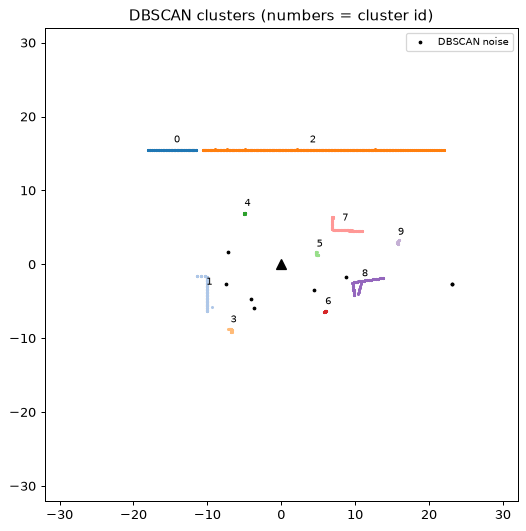

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 6))
cmap = plt.get_cmap("tab20")
for k in range(n_clusters):
    m = cl == k
    ax.scatter(Pobj[m, 0], Pobj[m, 1], s=2, color=cmap(k % 20))
    ax.text(Pobj[m, 0].mean(), Pobj[m, 1].mean() + 1, str(k), fontsize=8)
ax.scatter(Pobj[cl == -1, 0], Pobj[cl == -1, 1], s=4, c="black", label="DBSCAN noise")
ax.plot(0, 0, "k^", ms=8); ax.set_aspect("equal"); ax.set_xlim(-32, 32); ax.set_ylim(-32, 32)
ax.set_title("DBSCAN clusters (numbers = cluster id)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Which real objects did we find, and which did we lose? Because we simulated the scene, we can follow every object through the pipeline.

In [14]:
rows = []
for o in SCENE:
    m = Nobj == o["name"]
    found = np.unique(cl[m & (cl >= 0)])
    rows.append(dict(object=o["name"], distance_m=round(np.hypot(*o["center"]), 1),
                     raw_points=int(np.sum(NAMES == o["name"])), after_preprocessing=int(m.sum()),
                     dbscan_cluster=",".join(map(str, found)) if len(found) else "-"))
print(pd.DataFrame(rows).to_string(index=False))

object  distance_m  raw_points  after_preprocessing dbscan_cluster
 car_1        12.4         312                  190              8
 car_2        10.5         425                  222              7
 car_3        11.7         487                  212              1
 car_4        21.3          12                    2              -
  wall        16.1        3339                 2344            0,2
pole_1         8.8          95                   45              6
pole_2         8.6          96                   34              4
pole_3        25.7           7                    0              -
 ped_1         5.2         290                   40              5
 ped_2        16.3          23                   19              9
 ped_3        11.4          72                   37              3


Typical things you see in a table like this:
- **car_4 has (almost) no points**: it is parked right behind car_1, so it is **occluded**. No algorithm can detect what the sensor never saw; tracking (notebook 05) and other sensors help here.
- **pole_3** is thin and 26 m away, so it gets only a handful of points in one column of the range image. Downsampling, outlier removal and `min_samples` can easily delete it. Far, thin objects are the classic LiDAR weak spot.
- A large object (the wall) can be **split** into several clusters where something in front of it casts a shadow.

## 8. Bounding boxes: axis-aligned and oriented

**What it is.** A **bounding box** is the simplest description of an object: a centre, a size (length, width, height) and, for an **oriented** box, a heading angle (**yaw**).

| Box type | How it is computed | Good | Bad |
|---|---|---|---|
| **Axis-aligned (AABB)** | min and max of x, y, z | trivial, fast | too big for rotated objects |
| **Oriented (OBB)** | rotate to the main directions of the points (PCA), then min / max | tight fit, gives heading | PCA heading is unreliable when only one side of a car is visible |

**Why PCA can be wrong.** A LiDAR sees only the sides facing it, often an "L" shape. The direction of largest spread of an L can sit between the two sides. Real systems use **L-shape fitting** or a learned detector that predicts yaw directly.

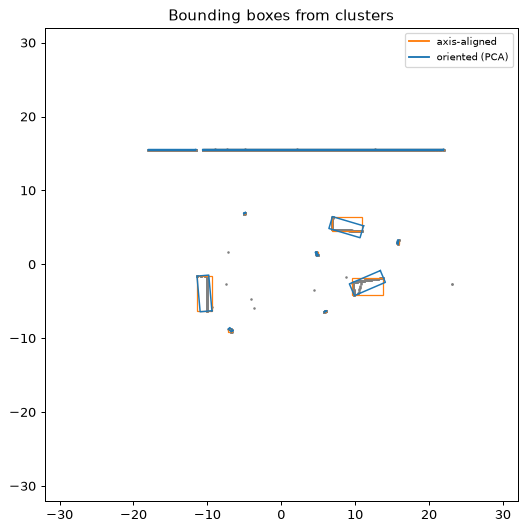

 cluster        cls     L    W    H  yaw_deg
       0   building  6.41 0.08 4.82    180.0
       1        car  4.84 1.60 1.70     95.1
       2   building 32.61 0.10 4.84    180.0
       3 pedestrian  0.56 0.28 1.44    134.7
       4       pole  0.24 0.11 2.72     24.8
       5 pedestrian  0.54 0.20 1.43    113.2
       6       pole  0.26 0.09 2.71     26.0
       7        car  4.39 1.68 1.36    163.5
       8        car  4.56 1.73 1.50     23.2
       9 pedestrian  0.50 0.17 1.18     77.1

True car yaws (deg, mod 180): [np.float64(8.0), np.float64(177.0), np.float64(90.0), np.float64(0.0)]


In [15]:
def aabb(pts):
    return pts[:, :3].min(axis=0), pts[:, :3].max(axis=0)

def obb_xy(pts):
    """Oriented box in the ground plane via PCA. Returns centre (x, y), length, width, yaw, z range."""
    xy = pts[:, :2]
    mu = xy.mean(axis=0)
    evals, evecs = np.linalg.eigh(np.cov((xy - mu).T))
    main = evecs[:, 1]                                  # direction of largest spread
    yaw = np.arctan2(main[1], main[0])
    R = np.array([[np.cos(yaw), -np.sin(yaw)], [np.sin(yaw), np.cos(yaw)]])
    local = (xy - mu) @ R                               # coordinates along the box axes
    lo, hi = local.min(axis=0), local.max(axis=0)
    centre = mu + R @ ((lo + hi) / 2)
    return dict(center=centre, length=hi[0] - lo[0], width=hi[1] - lo[1], yaw=yaw,
                zmin=pts[:, 2].min(), zmax=pts[:, 2].max(), R=R, lo=lo, hi=hi, mu=mu)

def obb_corners(b):
    lo, hi = b["lo"], b["hi"]
    local = np.array([[lo[0], lo[1]], [hi[0], lo[1]], [hi[0], hi[1]], [lo[0], hi[1]], [lo[0], lo[1]]])
    return b["mu"] + local @ b["R"].T

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(Pobj[:, 0], Pobj[:, 1], s=1, c="gray")
rows = []
for k in range(n_clusters):
    pk = Pobj[cl == k]
    lo, hi = aabb(pk)
    ax.add_patch(plt.Rectangle(lo[:2], *(hi - lo)[:2], fill=False, ec="tab:orange", lw=1))
    b = obb_xy(pk)
    cor = obb_corners(b); ax.plot(cor[:, 0], cor[:, 1], c="tab:blue", lw=1.2)
    rows.append(dict(cluster=k, cls=clusters_df.majority_class[k], L=round(b["length"], 2), W=round(b["width"], 2),
                     H=round(b["zmax"] - b["zmin"], 2), yaw_deg=round(np.rad2deg(b["yaw"]) % 180, 1)))
ax.plot([], [], c="tab:orange", label="axis-aligned"); ax.plot([], [], c="tab:blue", label="oriented (PCA)")
ax.set_aspect("equal"); ax.set_xlim(-32, 32); ax.set_ylim(-32, 32); ax.legend(fontsize=8)
ax.set_title("Bounding boxes from clusters"); plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).to_string(index=False))
print("\nTrue car yaws (deg, mod 180):", [round(np.rad2deg(o['yaw']) % 180, 1) for o in SCENE if o['cls'] == 'car'])

Compare the estimated car sizes and yaws with the truth (cars are about 4.2-4.8 m long and 1.8-1.9 m wide). Cars seen mostly from one side often get a box that is too short or too narrow, because the hidden sides have no points. This is exactly why learned 3D detectors predict the **full** box, including the parts nobody saw.

## 9. Bird's-eye-view (BEV) maps

**What it is.** A **BEV map** flattens the 3D cloud onto a 2D grid seen from above. Each grid cell stores a few numbers, for example: is anything here (**occupancy**), how tall is the tallest point (**max height**), how bright is the echo (**intensity**), how many points (**density**).

**Simple analogy.** A city map seen from a plane: you lose some 3D detail but you can now use ordinary 2D image tools.

**Why it matters.** Cars drive on a 2D ground, so planning happens in BEV. A BEV map is an "image" with several channels, so normal 2D **CNNs** (convolutional neural networks) can process it. Many detectors (PointPillars, CenterPoint) and fusion models (BEVFusion, section 11) work in BEV.

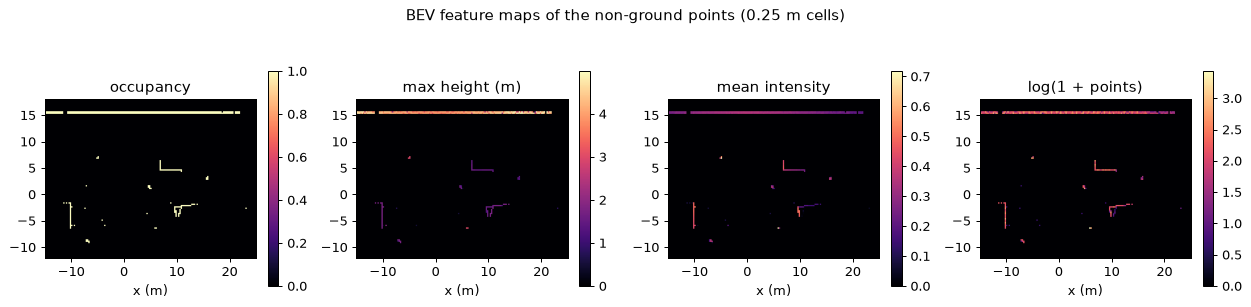

BEV grid shape: (240, 240) | occupied cells: 426


In [16]:
def bev_maps(pts, ground_z, cell=0.25, lim=30.0):
    """Return occupancy, max height above ground, mean intensity and log-density grids."""
    n = int(2 * lim / cell)
    ix = ((pts[:, 0] + lim) / cell).astype(int)
    iy = ((pts[:, 1] + lim) / cell).astype(int)
    m = (ix >= 0) & (ix < n) & (iy >= 0) & (iy < n)
    ix, iy, p = ix[m], iy[m], pts[m]
    count = np.zeros((n, n)); height = np.zeros((n, n)); inten = np.zeros((n, n))
    np.add.at(count, (iy, ix), 1)
    np.maximum.at(height, (iy, ix), p[:, 2] - ground_z)
    np.add.at(inten, (iy, ix), p[:, 3])
    with np.errstate(invalid="ignore"):
        inten = np.where(count > 0, inten / count, 0)
    return (count > 0).astype(float), height, inten, np.log1p(count)

ground_z = -d_g / n_g[2]
occ, hmax, inten, dens = bev_maps(Pobj, ground_z)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, img, title in zip(axes, [occ, hmax, inten, dens], ["occupancy", "max height (m)", "mean intensity", "log(1 + points)"]):
    im = ax.imshow(img, origin="lower", extent=[-30, 30, -30, 30], cmap="magma")
    ax.set_xlim(-15, 25); ax.set_ylim(-12, 18)          # zoom on the busy part of the street
    ax.set_title(title); ax.set_xlabel("x (m)")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle("BEV feature maps of the non-ground points (0.25 m cells)"); plt.tight_layout(); plt.show()
print("BEV grid shape:", occ.shape, "| occupied cells:", int(occ.sum()))

## 10. Registration with ICP (Iterative Closest Point)

**What it is.** **Registration** means finding the rotation $R$ and translation $t$ that line up two point clouds. If the car moved between two scans, registration tells you **how** it moved. **ICP** is the classic algorithm (Besl and McKay, 1992).

**Simple analogy.** You have two tracings of the same street drawn on transparent paper. Slide and turn the top sheet until the drawings overlap. ICP does this by repeatedly matching each point to its nearest point on the other sheet.

**How it works (point-to-point ICP).**

```mermaid
flowchart LR
    A[Start guess R, t] --> B[Move source points]
    B --> C[Match each source point<br/>to nearest target point]
    C --> D[Best R, t for these pairs<br/>closed form with SVD]
    D --> E{Error still<br/>dropping?}
    E -- yes --> B
    E -- no --> F[Done: R, t]
```

The best rotation for matched pairs has a closed-form answer (the **Kabsch** / Arun SVD method): centre both sets, build $H = \sum (a_i - \bar a)(b_i - \bar b)^T$, take $H = U S V^T$, then $R = V U^T$ and $t = \bar b - R \bar a$.

**When to use / when not.** ICP is precise when the starting guess is close (here: wheel odometry or an IMU gives one). With a bad start it can lock onto a wrong match (a **local minimum**). Variants: **point-to-plane ICP** (faster convergence on smooth surfaces), **GICP**, **NDT** (Normal Distributions Transform), and learned feature matching for a good initial guess.

We now simulate a second scan after the car drove 1.5 m forward, 0.4 m left, and turned 4 degrees.

In [17]:
TRUE_MOVE = dict(xy=(1.5, 0.4), yaw=np.deg2rad(4.0))
scan2 = lidar_scan(SCENE, sensor_xy=TRUE_MOVE["xy"], sensor_yaw=TRUE_MOVE["yaw"])
P2, _ = to_point_cloud(scan2)

def prep_for_icp(pts):
    """Keep non-ground points (simple height cut is enough here) and downsample."""
    pts = pts[(pts[:, 2] > -SENSOR_HEIGHT + 0.3) & (np.linalg.norm(pts[:, :2], axis=1) < 35)]
    out, _ = voxel_downsample(pts, np.zeros(len(pts)), voxel=0.3)
    return out[:, :3]

src, dst = prep_for_icp(P2), prep_for_icp(P)
print("source points (scan 2):", len(src), "| target points (scan 1):", len(dst))

def best_fit_transform(A, B):
    """Rigid R, t minimising sum |R a + t - b|^2 (Kabsch / SVD)."""
    ca, cb = A.mean(axis=0), B.mean(axis=0)
    H = (A - ca).T @ (B - cb)
    U, S, Vt = np.linalg.svd(H)
    R = Vt.T @ U.T
    if np.linalg.det(R) < 0:                 # avoid a mirror reflection
        Vt[-1] *= -1
        R = Vt.T @ U.T
    return R, cb - R @ ca

def icp(source, target, n_iter=50, max_dist=1.5, tol=1e-5):
    tree = cKDTree(target)
    R_total, t_total = np.eye(3), np.zeros(3)
    cur = source.copy(); errors = []
    for _ in range(n_iter):
        dist, idx = tree.query(cur)
        m = dist < max_dist                  # ignore pairs that are too far apart (probably wrong)
        R, t = best_fit_transform(cur[m], target[idx[m]])
        cur = cur @ R.T + t
        R_total, t_total = R @ R_total, R @ t_total + t
        errors.append(dist[m].mean())
        if len(errors) > 1 and abs(errors[-2] - errors[-1]) < tol:
            break
    return R_total, t_total, errors

R_est, t_est, errs = icp(src, dst)
yaw_est = np.rad2deg(np.arctan2(R_est[1, 0], R_est[0, 0]))
print(f"ICP iterations: {len(errs)}, mean match distance {errs[0]:.3f} m -> {errs[-1]:.3f} m")
print(f"estimated motion: x={t_est[0]:.3f} y={t_est[1]:.3f} z={t_est[2]:.3f} m, yaw={yaw_est:.2f} deg")
print(f"true motion:      x={TRUE_MOVE['xy'][0]:.3f} y={TRUE_MOVE['xy'][1]:.3f} z=0.000 m, yaw={np.rad2deg(TRUE_MOVE['yaw']):.2f} deg")

source points (scan 2): 2181 | target points (scan 1): 2046
ICP iterations: 14, mean match distance 0.675 m -> 0.148 m
estimated motion: x=1.226 y=0.393 z=-0.002 m, yaw=4.33 deg
true motion:      x=1.500 y=0.400 z=0.000 m, yaw=4.00 deg


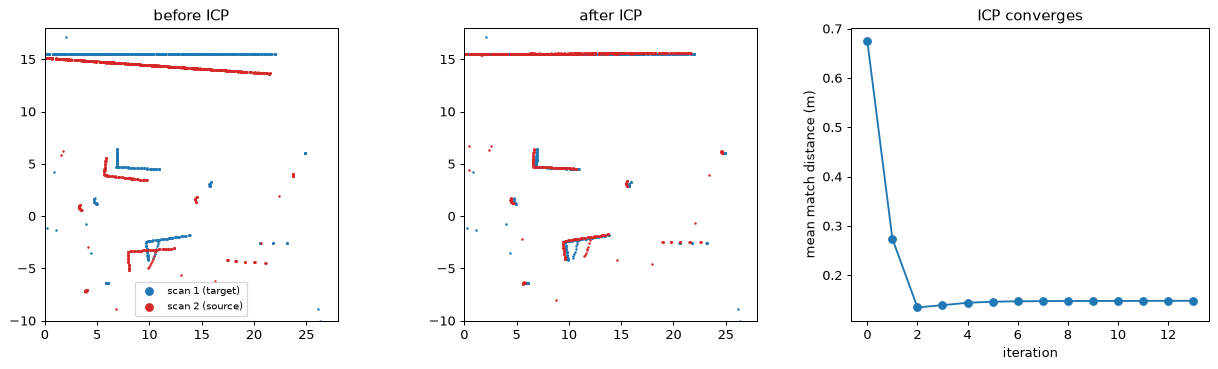

In [18]:
aligned = src @ R_est.T + t_est
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, s_, title in [(axes[0], src, "before ICP"), (axes[1], aligned, "after ICP")]:
    ax.scatter(dst[:, 0], dst[:, 1], s=1, c="tab:blue", label="scan 1 (target)")
    ax.scatter(s_[:, 0], s_[:, 1], s=1, c="tab:red", label="scan 2 (source)")
    ax.set_xlim(0, 28); ax.set_ylim(-10, 18); ax.set_aspect("equal"); ax.set_title(title)
axes[0].legend(markerscale=6, fontsize=8)
axes[2].plot(errs, "o-"); axes[2].set_xlabel("iteration"); axes[2].set_ylabel("mean match distance (m)")
axes[2].set_title("ICP converges")
plt.tight_layout(); plt.show()

The rotation is close, but the forward motion (x) is off by a few tens of centimetres. Two reasons:

- The two scans sample the surfaces at **different spots** (the laser rings land in different places after the car moved), so a point often has no true partner and gets pulled to the nearest wrong one.
- The long wall has many points but only tells us about y, not about x (sliding along a flat wall changes nothing). The few points on cars and poles must fix x alone, and their visible sides change between scans.

**Point-to-plane ICP** fixes most of this. It measures the error only **across** the target surface (along its **normal**, the direction pointing straight out of the surface), so sliding along a surface is free and sampling differences matter much less. Each step solves a small linear least-squares problem for a tiny rotation and a translation. Because it uses normals, it can also use the ground: the ground fixes z, roll and pitch.

In [19]:
def estimate_normals(pts, k=10):
    """Normal of each point = direction of least spread among its k nearest neighbours."""
    _, idx = cKDTree(pts).query(pts, k=k)
    nb = pts[idx] - pts[idx].mean(axis=1, keepdims=True)
    cov = np.einsum("nki,nkj->nij", nb, nb)
    _, vecs = np.linalg.eigh(cov)
    return vecs[:, :, 0]                                  # eigenvector of the smallest eigenvalue

def small_rotation(rx, ry, rz):
    Rx = np.array([[1, 0, 0], [0, np.cos(rx), -np.sin(rx)], [0, np.sin(rx), np.cos(rx)]])
    Ry = np.array([[np.cos(ry), 0, np.sin(ry)], [0, 1, 0], [-np.sin(ry), 0, np.cos(ry)]])
    Rz = np.array([[np.cos(rz), -np.sin(rz), 0], [np.sin(rz), np.cos(rz), 0], [0, 0, 1]])
    return Rz @ Ry @ Rx

def icp_point_to_plane(source, target, n_iter=50, max_dist=1.5, tol=1e-6):
    tree, normals = cKDTree(target), estimate_normals(target)
    R_total, t_total = np.eye(3), np.zeros(3)
    cur = source.copy(); errors = []
    for _ in range(n_iter):
        dist, idx = tree.query(cur)
        m = dist < max_dist
        p, q, n = cur[m], target[idx[m]], normals[idx[m]]
        # linearised error per pair: ((p x n) . angles) + (n . t) should equal (q - p) . n
        A = np.hstack([np.cross(p, n), n])
        b = np.einsum("ij,ij->i", q - p, n)
        x, *_ = np.linalg.lstsq(A, b, rcond=None)
        R, t = small_rotation(*x[:3]), x[3:]
        cur = cur @ R.T + t
        R_total, t_total = R @ R_total, R @ t_total + t
        errors.append(np.abs(b).mean())
        if len(errors) > 1 and abs(errors[-2] - errors[-1]) < tol:
            break
    return R_total, t_total, errors

def with_ground(pts):
    """Keep ALL points (including ground) within 35 m, downsampled."""
    pts = pts[np.linalg.norm(pts[:, :2], axis=1) < 35]
    return voxel_downsample(pts, np.zeros(len(pts)), voxel=0.3)[0][:, :3]

def describe(name, R, t):
    return dict(method=name, x=round(t[0], 3), y=round(t[1], 3), z=round(t[2], 3),
                yaw_deg=round(np.rad2deg(np.arctan2(R[1, 0], R[0, 0])), 2))

src_g, dst_g = with_ground(P2), with_ground(P)
R_pl, t_pl, _ = icp_point_to_plane(src_g, dst_g)
R_pg, t_pg, _ = icp(src_g, dst_g)
print(pd.DataFrame([
    dict(method="TRUE motion", x=TRUE_MOVE["xy"][0], y=TRUE_MOVE["xy"][1], z=0.0, yaw_deg=np.rad2deg(TRUE_MOVE["yaw"])),
    describe("point-to-point, non-ground points", R_est, t_est),
    describe("point-to-point, WITH ground points", R_pg, t_pg),
    describe("point-to-plane, WITH ground points", R_pl, t_pl),
]).to_string(index=False))

                            method     x     y      z  yaw_deg
                       TRUE motion 1.500 0.400  0.000     4.00
 point-to-point, non-ground points 1.226 0.393 -0.002     4.33
point-to-point, WITH ground points 0.143 0.204 -0.015     3.97
point-to-plane, WITH ground points 1.455 0.406 -0.005     4.01


Look at the middle row: **point-to-point ICP with ground points goes badly wrong**. The rings of ground points are centred on the sensor, so they move **with** the car. Matching ring to ring "proves" that the car did not move. This is a classic LiDAR pitfall. Point-to-plane ICP does not have the problem: a ground point may slide freely along the flat ground, so the ground only fixes height and tilt.

## 11. Mapping and SLAM (the idea)

**What it is.** **SLAM** (Simultaneous Localization And Mapping) builds a map of an unknown place **while** working out where the sensor is in that map. With LiDAR, the core step is the registration we just did.

**Simple analogy.** Walking through a dark house with a torch: you sketch each room as you see it, and use the walls you already drew to know where you are.

**How it works.**

```mermaid
flowchart LR
    A[New scan] --> B[Register to previous scan or map<br/>ICP / NDT, start from IMU guess]
    B --> C[Add pose to pose graph]
    C --> D{Back at a place<br/>seen before?}
    D -- yes: loop closure --> E[Optimise pose graph<br/>spread the drift correction]
    D -- no --> F[Add scan to map]
    E --> F
```

- **Odometry** = chaining scan-to-scan motions. Small errors add up, so the estimated path **drifts**.
- **Loop closure** = recognising a place you visited before, which gives a constraint that removes drift.
- **Pose graph optimisation** = adjust all poses together so every constraint is satisfied as well as possible.
- Well-known open-source LiDAR SLAM families include LOAM and its variants, and LIO (LiDAR-inertial odometry) systems that fuse an IMU (see [notebook 05](05_sensor_fusion_kalman_filters_and_tracking.ipynb)). [3D vision](../06_Computer_Vision/09_3d_vision.ipynb) covers visual SLAM.

Below, the smallest possible "map": both scans in one frame, using the point-to-plane ICP pose.

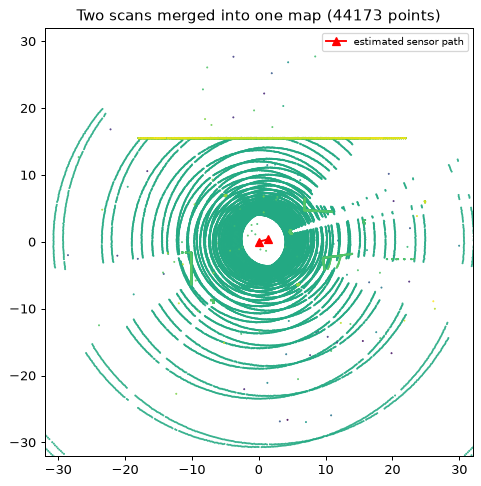

In [20]:
# use the more accurate point-to-plane pose
map_pts = np.vstack([P[:, :3], P2[:, :3] @ R_pl.T + t_pl])
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(map_pts[:, 0], map_pts[:, 1], s=0.3, c=map_pts[:, 2], cmap="viridis")
ax.plot([0, t_pl[0]], [0, t_pl[1]], "r^-", ms=7, label="estimated sensor path")
ax.set_xlim(-32, 32); ax.set_ylim(-32, 32); ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_title(f"Two scans merged into one map ({len(map_pts)} points)"); plt.tight_layout(); plt.show()

## 12. Deep learning on point clouds

A point cloud is awkward for normal neural networks:
- it is a **set**: the same cloud can be listed in any order, and the answer must not change (**permutation invariance**);
- the number of points changes from scan to scan;
- it is **sparse**: most of 3D space is empty.

### 12.1 PointNet: shared MLP + max-pool

**What it is.** **PointNet** (Qi et al., 2017) handles sets directly.
1. Apply the **same small MLP** (multi-layer perceptron) to every point on its own: each point becomes a feature vector. This is called a **shared MLP**.
2. Combine all point features with **max-pooling** over the points (take the maximum of each feature). The max does not care about order: it is a **symmetric function**.
3. A final MLP turns this global feature into class scores.

**Simple analogy.** A jury where every juror (point) writes down scores on their own, and the final decision only uses the highest score written for each question. Seat the jurors in any order: same result.

Below is an untrained PointNet forward pass in numpy (random weights). We only want to prove the invariance, not accuracy. We compare it with a naive network that flattens the points into one long vector.

In [21]:
def relu(x):
    return np.maximum(x, 0)

prng = np.random.default_rng(0)
W1, b1 = prng.normal(0, 0.5, (3, 32)), prng.normal(0, 0.1, 32)     # shared MLP layer 1: 3 -> 32
W2, b2 = prng.normal(0, 0.3, (32, 64)), prng.normal(0, 0.1, 64)    # shared MLP layer 2: 32 -> 64
Wc = prng.normal(0, 0.3, (64, 3))                                   # classifier head: 64 -> 3 classes

def pointnet_forward(pts):
    h = relu(relu(pts @ W1 + b1) @ W2 + b2)    # (N, 64): the SAME weights for every point
    g = h.max(axis=0)                          # (64,): symmetric max-pool over points
    return g @ Wc, h.argmax(axis=0)            # class scores, and which point won each feature

Wflat = prng.normal(0, 0.1, (200 * 3, 3))      # naive: flatten 200 points into a 600-long vector
def flat_forward(pts):
    return pts[:200].reshape(-1) @ Wflat

obj = Pobj[cl == 0][:, :3]                     # one cluster from our scene
obj = obj[prng.choice(len(obj), 200, replace=len(obj) < 200)]
shuffled = obj[prng.permutation(len(obj))]

s1, crit = pointnet_forward(obj); s2, _ = pointnet_forward(shuffled)
print("PointNet scores, original order:", s1)
print("PointNet scores, shuffled order:", s2, "-> identical:", np.allclose(s1, s2))
print("Flatten-MLP, original order:    ", flat_forward(obj))
print("Flatten-MLP, shuffled order:    ", flat_forward(shuffled), "-> identical:", np.allclose(flat_forward(obj), flat_forward(shuffled)))
print(f"\n'critical points' (points that win at least one max): {len(np.unique(crit))} of {len(obj)}")

PointNet scores, original order: [ 1.61  77.215 -4.352]
PointNet scores, shuffled order: [ 1.61  77.215 -4.352] -> identical: True
Flatten-MLP, original order:     [  2.937  -2.264 -34.633]
Flatten-MLP, shuffled order:     [ 11.076  -8.302 -39.951] -> identical: False

'critical points' (points that win at least one max): 13 of 200


Only some points win a max. PointNet's paper calls them **critical points**: the global feature depends only on them, which also makes PointNet robust to dropping other points. Its weakness is that it has no notion of **local neighbourhoods**. **PointNet++** fixes this by applying PointNet to small groups of nearby points, in several levels. Details and formulas: [3D vision notebook](../06_Computer_Vision/09_3d_vision.ipynb).

### 12.2 Grid-based detectors and BEV models (conceptual)

| Model family | Idea in one sentence | Why it matters |
|---|---|---|
| **VoxelNet** (2018) | Split space into voxels, run a small PointNet in each voxel, then 3D convolutions | first end-to-end learned voxel features |
| **SECOND** (2018) | Same idea with **sparse convolutions** that skip empty voxels | much faster; introduced "GT sampling" (copy-paste) augmentation |
| **PointPillars** (2019) | Use tall vertical columns (**pillars**) instead of cubes, so the result is a 2D BEV image for a fast 2D CNN | very fast, popular on embedded hardware |
| **CenterPoint** (2021) | Detect objects as **centre points** on the BEV map, then regress size and yaw | simple, strong, good for tracking |
| **BEV transformers** (BEVFormer, BEVFusion and others) | Use attention to lift camera images and/or LiDAR features into one shared BEV grid | the common "meeting place" for multi-sensor fusion (notebook 05) |

```mermaid
flowchart LR
    A[Raw points] --> B[Voxels or pillars]
    B --> C[Per-cell PointNet features]
    C --> D[BEV feature image]
    D --> E[2D CNN / transformer backbone]
    E --> F[Detection head:<br/>class, box centre, size, yaw]
```

## 13. Classify clusters with hand-made features (car / pedestrian / pole)

Before deep learning, a common approach was: cluster, compute a few **geometric features** per cluster, and train a classic classifier. It is still a great baseline and easy to debug.

**Training data.** We simulate many single objects at random distances, angles and sizes with the **same** sensor model, so the training clusters look like real scan clusters (partial views, fewer points when far).

**Features** (one row per cluster): number of points, distance, height, top height above ground, length, width, height spread, mean intensity.

In [22]:
def random_object(kind, rng):
    dist, ang = rng.uniform(4, 35), rng.uniform(-np.pi, np.pi)
    xy = (dist * np.cos(ang), dist * np.sin(ang))
    if kind == "car":
        return dict(cls="car", kind="box", center=xy, size=(rng.uniform(3.8, 5.0), rng.uniform(1.6, 2.0), rng.uniform(1.3, 1.8)),
                    z0=0.25, yaw=rng.uniform(-np.pi, np.pi), refl=rng.uniform(0.3, 0.8))
    if kind == "pedestrian":
        return dict(cls="pedestrian", kind="cyl", center=xy, radius=rng.uniform(0.22, 0.35), height=rng.uniform(1.5, 1.95), refl=rng.uniform(0.2, 0.6))
    return dict(cls="pole", kind="cyl", center=xy, radius=rng.uniform(0.08, 0.2), height=rng.uniform(3.0, 7.0), refl=rng.uniform(0.5, 0.95))

def cluster_features(pts):
    b = obb_xy(pts) if len(pts) >= 3 else dict(length=0, width=0)
    return dict(n_points=len(pts), distance=np.linalg.norm(pts[:, :2].mean(axis=0)),
                height=np.ptp(pts[:, 2]), top_above_ground=pts[:, 2].max() + SENSOR_HEIGHT,
                length=b["length"], width=b["width"], z_std=pts[:, 2].std(), mean_intensity=pts[:, 3].mean())

t0 = time.time()
feat_rows, y = [], []
for kind in ["car", "pedestrian", "pole"]:
    for _ in range(150):
        o = random_object(kind, rng)
        pts, lab = to_point_cloud(lidar_scan([o], dropout=0.03, outlier_rate=0.0))
        pts = pts[lab == 1]                        # keep only the object's points (as if after ground removal)
        if len(pts) >= 5:
            feat_rows.append(cluster_features(pts)); y.append(kind)
X = pd.DataFrame(feat_rows); y = np.array(y)
print(f"built {len(X)} training clusters in {time.time()-t0:.1f} s")
print(X.groupby(y).mean().round(2).to_string())

built 448 training clusters in 2.5 s
            n_points  distance  height  top_above_ground  length  width  z_std  mean_intensity
car           397.37     18.09    1.34              1.67    4.24   1.39   0.44            0.43
pedestrian     61.72     18.16    1.39              1.54    0.44   0.17   0.48            0.30
pole           42.70     19.19    3.80              3.98    0.16   0.07   1.19            0.57


In [23]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
clf = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(X_tr, y_tr)
pred = clf.predict(X_te)
labels = ["car", "pedestrian", "pole"]
print("test accuracy:", round(accuracy_score(y_te, pred), 3))
print(pd.DataFrame(confusion_matrix(y_te, pred, labels=labels), index=["true " + l for l in labels], columns=["pred " + l for l in labels]).to_string())
print("\nfeature importance:")
print(pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False).round(3).to_string())

test accuracy: 1.0
                 pred car  pred pedestrian  pred pole
true car               45                0          0
true pedestrian         0               45          0
true pole               0                0         45

feature importance:
length              0.261
top_above_ground    0.176
height              0.163
z_std               0.149
width               0.137
n_points            0.061
mean_intensity      0.044
distance            0.008


Now classify the clusters that DBSCAN found in our street scene. Very large clusters (longer than 6 m) are labelled "large structure" by a simple rule before the classifier, because the classifier never saw walls. Handling things your model has never seen (**out-of-distribution** inputs) is an important habit.

In [24]:
rows = []
for k in range(n_clusters):
    pk = Pobj[cl == k]
    f = cluster_features(pk)
    if f["length"] > 6.0:
        guess = "large structure"
    elif f["n_points"] < 5:
        guess = "too few points"
    else:
        guess = clf.predict(pd.DataFrame([f]))[0]
    rows.append(dict(cluster=k, points=f["n_points"], truth=clusters_df.majority_class[k], predicted=guess))
res = pd.DataFrame(rows)
print(res.to_string(index=False))
ok = res[res.truth.isin(labels)]
print(f"\ncorrect on car/pedestrian/pole clusters: {(ok.truth == ok.predicted).sum()} of {len(ok)}")

 cluster  points      truth       predicted
       0     369   building large structure
       1     213        car             car
       2    1975   building large structure
       3      37 pedestrian      pedestrian
       4      34       pole            pole
       5      40 pedestrian      pedestrian
       6      45       pole            pole
       7     222        car             car
       8     190        car             car
       9      19 pedestrian      pedestrian

correct on car/pedestrian/pole clusters: 8 of 8


## 14. LiDAR vs radar vs camera

| | LiDAR | Radar | Camera |
|---|---|---|---|
| Measures | 3D shape (range + angles), intensity | range, radial speed (Doppler), angle | colour, texture, text |
| Distance accuracy | very good (cm) | good | poor from one camera (must be inferred) |
| Angular resolution | good | low (improving with imaging radar) | very good |
| Speed measurement | only FMCW LiDAR, otherwise from frame differences | direct, per detection | from frame differences |
| Works in the dark | yes (own light) | yes | needs light (or infrared) |
| Rain, fog, dust, snow | degraded | robust | degraded |
| Reads signs, traffic lights, colours | no (only reflectivity) | no | yes |
| Cost (illustrative) | medium to high | low | low |
| Data size | large | small | large |

No single sensor wins everywhere, which is why cars and robots **fuse** them: see [05_sensor_fusion_kalman_filters_and_tracking.ipynb](05_sensor_fusion_kalman_filters_and_tracking.ipynb). Radar details are in [notebook 03](03_radar_fmcw_range_doppler_and_micro_doppler.ipynb).

## 15. Applications and tools

**Applications**

| Area | What LiDAR does there |
|---|---|
| Autonomous driving | 3D detection of cars, pedestrians, cyclists; localisation against a prior map; free-space estimation |
| Robotics and warehouses | obstacle avoidance, SLAM for mobile robots, safety zones around machines |
| Mapping and surveying | airborne and mobile mapping of cities, roads, power lines; digital elevation models |
| Forestry and agriculture | tree height and canopy structure from airborne LiDAR with multiple returns; biomass estimates |
| Phones and AR | some phones and tablets (for example recent Apple Pro models) include a small LiDAR for room scanning, AR placement and faster autofocus in the dark |
| Archaeology | airborne LiDAR "sees" ground shapes under forest canopy |

**Tools** (not needed for this notebook)

| Tool | What it is |
|---|---|
| **Open3D** | Python/C++ library: I/O, voxel downsampling, outlier removal, RANSAC plane, DBSCAN, ICP, visualisation |
| **PCL** (Point Cloud Library) | the classic C++ library with the same kinds of algorithms |
| **ROS / ROS 2** (Robot Operating System) | middleware that moves sensor messages (for example `sensor_msgs/PointCloud2`) between programs, with tools for recording (bags) and visualising (RViz) |
| Deep learning toolkits | OpenPCDet, MMDetection3D: training code for VoxelNet, PointPillars, CenterPoint and others |
| File formats | `.pcd` (PCL), `.ply`, `.las` / `.laz` (aerial survey), `.bin` (KITTI raw float arrays) |

For reference, the Open3D version of our pipeline looks roughly like this (shown only, not run):

```python
import open3d as o3d
pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(xyz))
pcd = pcd.voxel_down_sample(voxel_size=0.2)
pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=8, std_ratio=2.0)
plane, ground_idx = pcd.segment_plane(distance_threshold=0.15, ransac_n=3, num_iterations=100)
objects = pcd.select_by_index(ground_idx, invert=True)
labels = objects.cluster_dbscan(eps=0.7, min_points=5)
reg = o3d.pipelines.registration.registration_icp(source, target, 1.5)   # reg.transformation is 4x4
```

In [25]:
# Optional check: is Open3D installed? (It is NOT required.)
try:
    import open3d  # noqa: F401
    print("open3d is installed, version", open3d.__version__)
except Exception:
    print("skipped: needs open3d (optional) - everything above was done with numpy/scipy/sklearn")

skipped: needs open3d (optional) - everything above was done with numpy/scipy/sklearn


## 16. Recap / cheat sheet

| Step | What it does | Our implementation | Key knobs |
|---|---|---|---|
| Time of flight | distance = c * dt / 2 | section 1 | timing precision, pulse rate |
| Spherical to Cartesian | (r, elevation, azimuth) -> (x, y, z) | `ranges_to_xyz` | sensor axis convention |
| Organized cloud | range image (beams x azimuth) | `lidar_scan` | channels, angular resolution |
| Crop | keep a region of interest | `crop` | box limits |
| Voxel downsampling | one averaged point per voxel | `voxel_downsample` | voxel size |
| Outlier removal | drop isolated points | `statistical_outlier_removal` | k, number of std |
| Ground removal | RANSAC plane | `ransac_plane` | distance threshold, iterations, tilt limit |
| Clustering | group nearby points into objects | `DBSCAN` | eps, min_samples |
| Bounding boxes | AABB, PCA-oriented box | `aabb`, `obb_xy` | L-shape problem for partial views |
| BEV maps | 2D grid of occupancy / height / intensity | `bev_maps` | cell size, range |
| Registration | find R, t between scans | `icp` (Kabsch SVD), `icp_point_to_plane` | initial guess, max match distance, ground handling |
| PointNet | shared MLP + max-pool = order does not matter | `pointnet_forward` | - |
| Cluster classification | features + random forest | section 13 | features, out-of-distribution rules |

## 17. Interview questions

1. **How does a ToF LiDAR measure distance?** It times a laser pulse's round trip: $d = c\,\Delta t / 2$. 1 ns of timing error is about 15 cm.
2. **What extra information does an FMCW LiDAR give?** The radial velocity of every point, from the Doppler shift, plus better robustness to sunlight and other LiDARs.
3. **Why do some LiDARs use 1550 nm?** That light is mostly absorbed before it reaches the retina, so more power is eye-safe, which allows longer range; the detectors cost more.
4. **Organized vs unorganized point cloud?** Organized keeps the sensor's grid (range image), so neighbours are free; unorganized is a plain list and needs a k-d tree for neighbours.
5. **Why remove the ground before clustering?** The ground connects all objects; without removing it, DBSCAN would merge everything into one cluster.
6. **How many RANSAC iterations do you need?** $N = \log(1-p)/\log(1-w^3)$ for a plane, where $w$ is the inlier fraction and $p$ the desired success probability.
7. **When does ICP fail?** With a poor initial guess (local minimum), in feature-poor places (long tunnels, open fields), or with many moving objects. Fixes: IMU/odometry initial guess, point-to-plane ICP, outlier rejection, robust losses.
8. **Why is PointNet permutation invariant?** It applies the same MLP to each point independently and then uses max-pooling, a symmetric function whose output does not depend on order.
9. **Why are BEV representations popular?** Driving happens on a plane, BEV images can use fast 2D CNNs, object sizes do not change with distance, and BEV is a natural common space for fusing LiDAR, radar and cameras.
10. **Your detector misses far pedestrians. What do you check?** Points per object at that range (beam spacing), voxel size and outlier filter settings, DBSCAN `min_samples`, class balance in training data, and augmentation (see [notebook 06](06_sensor_data_for_generative_and_foundation_models.ipynb)).

## 18. Further reading

- P. J. Besl and N. D. McKay, "A Method for Registration of 3-D Shapes", *IEEE TPAMI*, 1992 (ICP).
- K. S. Arun, T. S. Huang and S. D. Blostein, "Least-Squares Fitting of Two 3-D Point Sets", *IEEE TPAMI*, 1987 (the SVD solution used in ICP).
- M. A. Fischler and R. C. Bolles, "Random Sample Consensus", *Communications of the ACM*, 1981 (RANSAC).
- M. Ester, H.-P. Kriegel, J. Sander and X. Xu, "A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise", KDD 1996 (DBSCAN).
- R. B. Rusu et al., "Towards 3D Point Cloud Based Object Maps for Household Environments", 2008 (statistical outlier removal, as used in PCL).
- C. R. Qi, H. Su, K. Mo and L. J. Guibas, "PointNet: Deep Learning on Point Sets for 3D Classification and Segmentation", CVPR 2017, arXiv:1612.00593.
- Y. Zhou and O. Tuzel, "VoxelNet: End-to-End Learning for Point Cloud Based 3D Object Detection", CVPR 2018, arXiv:1711.06396.
- A. H. Lang et al., "PointPillars: Fast Encoders for Object Detection from Point Clouds", CVPR 2019, arXiv:1812.05784.
- T. Yin, X. Zhou and P. Krahenbuhl, "Center-based 3D Object Detection and Tracking" (CenterPoint), CVPR 2021, arXiv:2006.11275.
- J. Zhang and S. Singh, "LOAM: Lidar Odometry and Mapping in Real-time", RSS 2014.
- Open3D documentation (open3d.org), Point Cloud Library (pointclouds.org), ROS 2 documentation (docs.ros.org).
- Datasets: KITTI, nuScenes, Waymo Open Dataset.

## Where to go next

- [05_sensor_fusion_kalman_filters_and_tracking.ipynb](05_sensor_fusion_kalman_filters_and_tracking.ipynb): project LiDAR into a camera, fuse LiDAR with radar in a Kalman filter, track many objects.
- [06_sensor_data_for_generative_and_foundation_models.ipynb](06_sensor_data_for_generative_and_foundation_models.ipynb): point-cloud augmentation, simulation, synthetic data and foundation models.
- [3D computer vision](../06_Computer_Vision/09_3d_vision.ipynb): PointNet++, NeRF, Gaussian splatting, 3D detection benchmarks.
- Track overview: [README.md](README.md).

In [26]:
print(f"Notebook finished in {time.time() - T_START:.1f} s")

Notebook finished in 6.8 s
